# T02 | Predicting outdoor heat-stress events in weather streams
**Data Stream Mining — Final Project | Portimão (City A) and Covilhã (City B)**

**Project team:**  
Diogo Caldeirinha — 20231689  
Arsenii Prorokov — 20230784  
Vladislav Botnev — 20230795  
Victoriya Mokhovikova — 20230796  
Yan Sidoryk — 20222004  
 
**Business setting:** Outdoor Workforce Scheduling Service  
**Assigned event:** Heat Stress Event  
**Historical archive:** Open-Meteo ERA5, hourly, 2016–2025

We use a common chronological protocol to characterise both city streams, and compare seven incremental classifiers under two feature representations.

**Final project extension (FP-T02).** Sections 6–7 add UnimPA and UnimSafe to the PA44 replay and inspect their evolving rules.

## 1. Business context and experimental choices
Our assigned question is: **Which location presents fewer high-temperature stress periods for outdoor workers?** Weather alone can inform this operational dimension; it cannot determine overall business suitability.

We define an illustrative shift as **Monday–Friday, 08:00–18:00 Europe/Lisbon time** (no holiday exclusions).

## 2. Data and stream construction
### 2.1 Environment, project folders and data retrieval
We collect four hourly ERA5 variables: temperature (°C), relative humidity (%), precipitation (mm) and 10-m wind speed (km/h). We cache the unaltered API responses in `data/raw/` so repeated runs reuse the same snapshots. All stream operations use **UTC** timestamps; the work-shift calendar uses **Europe/Lisbon** local time, including daylight-saving transitions.

In [ ]:
import time
notebook_start = time.time()

In [1]:
from __future__ import annotations

import importlib.metadata as metadata
import json
import platform
import sys
import time
from collections import deque
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from requests.adapters import HTTPAdapter
from sklearn.preprocessing import StandardScaler
from urllib3.util.retry import Retry

# Resolve the project root whether Jupyter starts in the root or in src/.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'src':
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src').is_dir():
    raise RuntimeError('Open the notebook inside the provided PA44 project folder.')

RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
RESULTS_DIR = PROJECT_ROOT / 'results'
TABLES_DIR = RESULTS_DIR / 'tables'
FIGURES_DIR = RESULTS_DIR / 'figures'
for directory in (RAW_DIR, PROCESSED_DIR, RESULTS_DIR, TABLES_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

PA_CODE = 'PA44'
CITIES = {
    'Portimão': {'latitude': 37.1366, 'longitude': -8.5377},
    'Covilhã': {'latitude': 40.2806, 'longitude': -7.5039},
}
CITY_A, CITY_B = CITIES
START_DATE, END_DATE = '2016-01-01', '2025-12-31'
WARMUP_END_UTC = pd.Timestamp('2017-12-31 23:00:00', tz='UTC')
LOCAL_TZ = 'Europe/Lisbon'
SHIFT_START, SHIFT_END = 8, 18  # Inclusive start, exclusive end.
RAW_VARIABLES = [
    'temperature_2m', 'relative_humidity_2m',
    'precipitation', 'wind_speed_10m',
]
ARCHIVE_URL = 'https://archive-api.open-meteo.com/v1/archive'
WEATHER_MODEL = 'era5'
TARGET_QUANTILE = 0.80
RANDOM_SEED = 42
SEEDS = list(range(42, 52))  # 42, 43, ..., 51
ENSEMBLE_SIZE = 5
ROLLING_SCORE_WINDOW = 300
CHECKPOINT_EVERY = 250
FORCE_DOWNLOAD = False  # Change only to deliberately refresh snapshots.

np.random.seed(RANDOM_SEED)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'font.size': 10})


def installed_version(package):
    try:
        return metadata.version(package)
    except metadata.PackageNotFoundError:
        return 'not installed'


def save_figure(filename):
    plt.savefig(FIGURES_DIR / filename, bbox_inches='tight')
    plt.show()
    plt.close()


RUN_CONFIG = {
    'assignment': PA_CODE,
    'cities': list(CITIES),
    'period': [START_DATE, END_DATE],
    'warmup_end_utc': WARMUP_END_UTC.isoformat(),
    'working_hours': 'Mon–Fri, 08:00–17:59 Europe/Lisbon',
    'weather_model': WEATHER_MODEL,
    'target': 'T2 — pooled 2016-2017 warm-up temperature 80th percentile',
    'random_seed': RANDOM_SEED,
    'seeds': SEEDS,
    'ensemble_size': ENSEMBLE_SIZE,
    'python_version': platform.python_version(),
    'packages': {p: installed_version(p) for p in (
        'numpy', 'pandas', 'matplotlib', 'requests', 'scikit-learn', 'river')},
    'generated_utc': datetime.now(timezone.utc).isoformat(),
}
(RESULTS_DIR / 'environment.json').write_text(
    json.dumps(RUN_CONFIG, indent=2, ensure_ascii=False), encoding='utf-8'
)
print('Project:', PROJECT_ROOT)
print('Python:', RUN_CONFIG['python_version'], '| Random seed:', RANDOM_SEED)

Project: C:\Users\diogo\Desktop\DSM_FinalProject
Python: 3.14.3 | Random seed: 42


In [2]:
def fetch_year(city, year):
    """Read a cached unmodified API payload, or download it once."""
    file = RAW_DIR / f'{city.lower().replace("ã", "a").replace("í", "i")}_{year}_{WEATHER_MODEL}.json'
    if file.exists() and not FORCE_DOWNLOAD:
        payload = json.loads(file.read_text(encoding='utf-8'))
        origin = 'cached'
    else:
        location = CITIES[city]
        params = {
            'latitude': location['latitude'], 'longitude': location['longitude'],
            'start_date': f'{year}-01-01', 'end_date': f'{year}-12-31',
            'hourly': ','.join(RAW_VARIABLES), 'models': WEATHER_MODEL,
            'timezone': 'GMT', 'temperature_unit': 'celsius',
            'wind_speed_unit': 'kmh', 'precipitation_unit': 'mm',
        }
        retry = Retry(total=4, backoff_factor=1.5,
                      status_forcelist=[429, 500, 502, 503, 504])
        with requests.Session() as session:
            session.mount('https://', HTTPAdapter(max_retries=retry))
            try:
                response = session.get(ARCHIVE_URL, params=params, timeout=(15, 120))
                response.raise_for_status()
                payload = response.json()
            except requests.RequestException as error:
                raise RuntimeError(f'Cannot retrieve {city}, {year}: {error}') from error
        if payload.get('error'):
            raise RuntimeError(f'Open-Meteo error for {city}: {payload.get("reason")}')
        file.write_text(json.dumps(payload, ensure_ascii=False), encoding='utf-8')
        origin = 'downloaded'

    hourly = payload.get('hourly', {})
    if 'time' not in hourly or any(column not in hourly for column in RAW_VARIABLES):
        raise ValueError(f'Unexpected API fields in {file.name}')
    n = len(hourly['time'])
    if any(len(hourly[column]) != n for column in RAW_VARIABLES):
        raise ValueError(f'Inconsistent hourly array lengths in {file.name}')
    return payload, {'city': city, 'year': year, 'file': file.name,
                     'source': origin, 'hours_received': n}


def payload_to_frame(payload, city):
    """Parse GMT timestamps as UTC; never discard missing hours."""
    hourly = payload['hourly']
    timestamps = pd.DatetimeIndex(pd.to_datetime(hourly['time'], utc=True),
                                  name='timestamp_utc')
    if timestamps.has_duplicates:
        raise ValueError(f'{city}: duplicate timestamps in an API response')
    values = {name: pd.to_numeric(pd.Series(hourly[name]), errors='coerce').to_numpy()
              for name in RAW_VARIABLES}
    return pd.DataFrame(values, index=timestamps).sort_index()


def load_weather(city):
    yearly_frames = []
    for year in range(2016, 2026):
        payload, record = fetch_year(city, year)
        retrieval_log.append(record)
        yearly_frames.append(payload_to_frame(payload, city))
    frame = pd.concat(yearly_frames).sort_index()
    if frame.index.has_duplicates:
        raise ValueError(f'{city}: duplicate timestamps across yearly snapshots')
    expected = pd.date_range('2016-01-01 00:00', '2025-12-31 23:00',
                             freq='h', tz='UTC', name='timestamp_utc')
    if not frame.index.difference(expected).empty:
        raise ValueError(f'{city}: unexpected dates outside the chosen period')
    return frame.reindex(expected)  # Gaps become missing values, not hidden deletions.


retrieval_log = []
weather = {city: load_weather(city) for city in CITIES}
pd.DataFrame(retrieval_log).to_csv(PROCESSED_DIR / 'source_manifest.csv', index=False)
assert weather[CITY_A].index.equals(weather[CITY_B].index)
print('Loaded shared UTC calendar:', len(weather[CITY_A]), 'hourly timestamps')

Loaded shared UTC calendar: 87672 hourly timestamps


### 2.2 Quality assessment and stream integrity
We count missing values, check basic physical-domain constraints and flag unusually extreme observations for review. **We never remove extremes automatically.** Missing timestamps remain explicit. If clearly invalid values are encountered, execution stops for documented investigation rather than silently altering the stream.

In [3]:
def quality_audit(data):
    rows = []
    for city, frame in data.items():
        for variable in RAW_VARIABLES:
            values = frame[variable]
            observed = values.dropna()
            q1, q3 = observed.quantile([0.25, 0.75])
            iqr = q3 - q1
            broad_extremes = ((observed < q1 - 3 * iqr) |
                              (observed > q3 + 3 * iqr)).sum()
            invalid = ~np.isfinite(observed.to_numpy(dtype=float))
            if variable == 'relative_humidity_2m':
                invalid |= ((observed < 0) | (observed > 100)).to_numpy()
            elif variable in ('precipitation', 'wind_speed_10m'):
                invalid |= (observed < 0).to_numpy()
            elif variable == 'temperature_2m':
                invalid |= ((observed < -90) | (observed > 70)).to_numpy()
            rows.append({
                'city': city, 'variable': variable,
                'calendar_hours': len(frame), 'missing_n': int(values.isna().sum()),
                'missing_pct': 100 * float(values.isna().mean()),
                'min': observed.min(), 'median': observed.median(),
                'max': observed.max(), 'wide_iqr_review_flags': int(broad_extremes),
                'invalid_domain_n': int(invalid.sum()),
            })
    return pd.DataFrame(rows)


quality = quality_audit(weather)
display(quality.round(2))
quality.to_csv(TABLES_DIR / 'data_quality.csv', index=False)
if quality['invalid_domain_n'].sum() > 0:
    raise RuntimeError('Invalid physical-domain values found. Investigate raw snapshots '
                       'and document a correction before running the analysis.')
print('Wide-IQR flags are descriptive review flags, not automatic deletion rules.')

,city,variable,calendar_hours,missing_n,missing_pct,min,median,max,wide_iqr_review_flags,invalid_domain_n
0,Portimão,temperature_2m,87672,0,0.0,-0.9,17.6,44.3,0,0
1,Portimão,relative_humidity_2m,87672,0,0.0,10.0,74.0,100.0,0,0
2,Portimão,precipitation,87672,0,0.0,0.0,0.0,9.3,7567,0
3,Portimão,wind_speed_10m,87672,0,0.0,0.0,11.8,51.9,2,0
4,Covilhã,temperature_2m,87672,0,0.0,-4.1,13.1,39.4,0,0
5,Covilhã,relative_humidity_2m,87672,0,0.0,8.0,74.0,100.0,0,0
6,Covilhã,precipitation,87672,0,0.0,0.0,0.0,11.3,14612,0
7,Covilhã,wind_speed_10m,87672,0,0.0,0.0,8.0,33.5,123,0


Wide-IQR flags are descriptive review flags, not automatic deletion rules.


### 2.3 Fixed pooled warm-up threshold and leakage-free predictors
We build the work-hour calendar **before inspecting target values**. The warm-up ends on 31 December 2017. We calculate one shared 80th-percentile threshold from all observed **eligible work-hour temperatures in 2016–2017**, using both cities. The current temperature then defines the label but does not appear in any feature representation.

Representation A and B are constructed from the uninterrupted hourly weather archive before we filter to scheduled work hours; overnight and weekend weather therefore remains available as past context. Missing predictor values are handled **later**, using medians fitted only to warm-up records.

In [4]:
REP_A = [f'lag1_{variable}' for variable in RAW_VARIABLES]
REP_B = REP_A + [
    'temperature_change_1h',
    'temperature_mean_6h',
    'temperature_std_6h',
    'humidity_mean_6h',
    'rainy_hours_24h',
    'shift_hour_sin',
    'shift_hour_cos',
]
assert len(REP_A) == 4 and len(REP_B) == 11
assert 'temperature_2m' not in REP_A + REP_B
assert len(set(REP_B)) == len(REP_B)


def shift_mask(timestamps):
    local = timestamps.tz_convert(LOCAL_TZ)
    return (local.weekday < 5) & (local.hour >= SHIFT_START) & (local.hour < SHIFT_END)


# Fix the boundary using the calendar, not a data-dependent count of valid labels.
calendar = weather[CITY_A].index
eligible_calendar = calendar[shift_mask(calendar)]
warm_calendar = eligible_calendar[eligible_calendar <= WARMUP_END_UTC]
eval_calendar = eligible_calendar[eligible_calendar > WARMUP_END_UTC]

warm_temperatures = pd.concat(
    [weather[city].loc[warm_calendar, 'temperature_2m'].dropna() for city in CITIES],
    ignore_index=True,
)
if len(warm_temperatures) < 100:
    raise RuntimeError('Too few pooled observed warm-up temperatures.')
HOT_THRESHOLD_C = float(warm_temperatures.quantile(TARGET_QUANTILE))


def construct_stream(frame, threshold):
    """Build a target at t and predictors from data available strictly before t."""
    out = pd.DataFrame(index=frame.index)
    local = frame.index.tz_convert(LOCAL_TZ)
    out['local_date'] = local.date
    out['local_month'] = local.month
    out['local_hour'] = local.hour
    out['eligible_shift'] = shift_mask(frame.index)

    temperature = frame['temperature_2m']
    target = (temperature >= threshold).astype('Int64')
    out['y_event'] = target.where(temperature.notna(), pd.NA)

    # shift(1) means the latest weather information is at t-1.
    for variable in RAW_VARIABLES:
        out[f'lag1_{variable}'] = frame[variable].shift(1)
    earlier_temperature = temperature.shift(1)
    out['temperature_change_1h'] = temperature.shift(1) - temperature.shift(2)
    out['temperature_mean_6h'] = earlier_temperature.rolling(6, min_periods=4).mean()
    out['temperature_std_6h'] = earlier_temperature.rolling(6, min_periods=4).std(ddof=0)
    out['humidity_mean_6h'] = frame['relative_humidity_2m'].shift(1).rolling(
        6, min_periods=4).mean()
    observed_rain = (frame['precipitation'] >= 0.1).astype(float)
    observed_rain = observed_rain.where(frame['precipitation'].notna(), np.nan)
    out['rainy_hours_24h'] = observed_rain.shift(1).rolling(24, min_periods=18).sum()

    # Calendar features are known before the target hour begins.
    out['shift_hour_sin'] = np.sin(2 * np.pi * local.hour / 24)
    out['shift_hour_cos'] = np.cos(2 * np.pi * local.hour / 24)
    return out


stream_full = {city: construct_stream(frame, HOT_THRESHOLD_C)
               for city, frame in weather.items()}
threshold_record = {
    'quantile': TARGET_QUANTILE, 'threshold_celsius': HOT_THRESHOLD_C,
    'warmup_first_utc': str(warm_calendar.min()),
    'warmup_last_utc': str(warm_calendar.max()),
    'pooled_observed_warmup_hours': int(len(warm_temperatures)),
    'warmup_city_counts': {city: int(weather[city].loc[warm_calendar, 'temperature_2m'].count())
                           for city in CITIES},
}
(RESULTS_DIR / 'target_definition.json').write_text(
    json.dumps(threshold_record, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'Frozen T2 threshold: {HOT_THRESHOLD_C:.3f} °C '
      f'(pooled 2016-2017 work-hour 80th percentile; n={len(warm_temperatures):,}).')

Frozen T2 threshold: 26.100 °C (pooled 2016-2017 work-hour 80th percentile; n=10,420).


In [5]:
# Synthetic alignment test: modifying current or future weather cannot modify X_t.
fixture_times = pd.date_range('2024-06-01', periods=100, freq='h', tz='UTC')
fixture = pd.DataFrame({
    'temperature_2m': 20 + np.sin(np.arange(100) / 6),
    'relative_humidity_2m': 55 + np.cos(np.arange(100) / 5),
    'precipitation': np.zeros(100),
    'wind_speed_10m': np.full(100, 7.0),
}, index=fixture_times)
original = construct_stream(fixture, 20.5)
modified_fixture = fixture.copy()
modified_fixture.loc[fixture_times[70], 'temperature_2m'] = 65.0
modified = construct_stream(modified_fixture, 20.5)
pd.testing.assert_series_equal(
    original.loc[fixture_times[70], REP_B], modified.loc[fixture_times[70], REP_B]
)
assert original.loc[fixture_times[70], 'y_event'] != modified.loc[fixture_times[70], 'y_event']
assert original.loc[fixture_times[70], 'lag1_temperature_2m'] == fixture.loc[
    fixture_times[69], 'temperature_2m']
print('PASS — changing temperature(t) changes the label, not predictors X(t).')

PASS — changing temperature(t) changes the label, not predictors X(t).


### 2.4 Common replay cohort and frozen preprocessing
We score only hours where **both cities have an observed current-hour temperature**; therefore every city and model receives the same chronological evaluation timestamps. We report excluded hours in the audit table. Within this cohort, we fit missing-feature medians and a standard scaler on the pooled **2016–2017 warm-up only**, then reuse these frozen values during 2018–2025. No missing target is imputed.

In [6]:
# Cohort membership is determined from the work calendar and observed labels.
labeled_by_city = {
    city: stream_full[city].loc[eligible_calendar, 'y_event'].notna()
    for city in CITIES
}
paired_valid = labeled_by_city[CITY_A] & labeled_by_city[CITY_B]
model_times = eligible_calendar[paired_valid.to_numpy()]
warm_times = model_times[model_times <= WARMUP_END_UTC]
eval_times = model_times[model_times > WARMUP_END_UTC]
if len(warm_times) < 100 or len(eval_times) < 100:
    raise RuntimeError('Not enough paired labeled work hours for a valid experiment.')
assert warm_times.is_monotonic_increasing and eval_times.is_monotonic_increasing
assert warm_times.max() < eval_times.min()

cohort = pd.DataFrame([{
    'city': city,
    'scheduled_calendar_hours': len(eligible_calendar),
    'warmup_scheduled_hours': len(warm_calendar),
    'evaluation_scheduled_hours': len(eval_calendar),
    'city_missing_target_hours': int((~labeled_by_city[city]).sum()),
    'paired_warmup_hours': len(warm_times),
    'paired_evaluation_hours': len(eval_times),
    'paired_excluded_hours': len(eligible_calendar) - len(model_times),
} for city in CITIES])
cohort.to_csv(TABLES_DIR / 'cohort_audit.csv', index=False)
display(cohort)

# Descriptive class balance for both phases (not used to fit a threshold or tune a model).
class_rows = []
for city in CITIES:
    for phase, timestamps in (('warmup', warm_times), ('evaluation', eval_times)):
        labels = stream_full[city].loc[timestamps, 'y_event'].astype(int)
        event_n = int(labels.sum())
        class_rows.append({
            'city': city, 'phase': phase, 'observed_paired_hours': len(labels),
            'non_event_n': len(labels) - event_n, 'event_n': event_n,
            'event_rate_pct': 100 * event_n / len(labels),
        })
class_distribution = pd.DataFrame(class_rows)
class_distribution.to_csv(TABLES_DIR / 'class_distribution_by_phase.csv', index=False)
display(class_distribution.round(2))

# Median imputation and scaling are learned from the exact pooled warm-up cohort.
pooled_warmup = pd.concat(
    [stream_full[city].loc[warm_times, REP_B] for city in CITIES],
    ignore_index=True,
)
warm_medians = pooled_warmup.median(numeric_only=True)
if warm_medians.isna().any():
    raise RuntimeError('An entire warm-up feature is missing: '
                       + ', '.join(warm_medians.index[warm_medians.isna()]))

feature_audit = []
scaled_inputs = {}
scaler_config = {}
for representation, features in (('A', REP_A), ('B', REP_B)):
    fitted_scaler = StandardScaler().fit(pooled_warmup[features].fillna(warm_medians))
    scaler_config[representation] = {
        'features': features,
        'means': fitted_scaler.mean_.tolist(),
        'scales': fitted_scaler.scale_.tolist(),
    }
    for city in CITIES:
        unscaled = stream_full[city].loc[model_times, features]
        for feature in features:
            feature_audit.append({
                'city': city, 'representation': representation, 'feature': feature,
                'missing_predictor_n': int(unscaled[feature].isna().sum()),
                'pooled_warmup_imputation_median': float(warm_medians[feature]),
            })
        prepared = unscaled.fillna(warm_medians)
        array = fitted_scaler.transform(prepared)
        if not np.isfinite(array).all():
            raise RuntimeError(f'{city}, {representation}: non-finite prepared features')
        scaled_inputs[(city, representation)] = pd.DataFrame(
            array, index=model_times, columns=features,
        )

feature_audit_df = pd.DataFrame(feature_audit)
feature_audit_df.to_csv(TABLES_DIR / 'feature_missingness_imputation.csv', index=False)
(RESULTS_DIR / 'preprocessing.json').write_text(
    json.dumps(scaler_config, indent=2), encoding='utf-8')

for city in CITIES:
    # Store labeled model rows with the unscaled, interpretable features.
    prepared_stream = stream_full[city].loc[model_times, ['y_event', 'eligible_shift'] + REP_B]
    prepared_stream.to_csv(PROCESSED_DIR / f'{"city_A" if city == CITY_A else "city_B"}_model_stream.csv')

print(f'Paired labeled hours: {len(warm_times):,} warm-up, {len(eval_times):,} evaluation.')
print('Predictor imputation and scaling: pooled warm-up statistics only.')

,city,scheduled_calendar_hours,warmup_scheduled_hours,evaluation_scheduled_hours,city_missing_target_hours,paired_warmup_hours,paired_evaluation_hours,paired_excluded_hours
0,Portimão,26090,5210,20880,0,5210,20880,0
1,Covilhã,26090,5210,20880,0,5210,20880,0


,city,phase,observed_paired_hours,non_event_n,event_n,event_rate_pct
0,Portimão,warmup,5210,3855,1355,26.01
1,Portimão,evaluation,20880,16025,4855,23.25
2,Covilhã,warmup,5210,4446,764,14.66
3,Covilhã,evaluation,20880,18177,2703,12.95


Paired labeled hours: 5,210 warm-up, 20,880 evaluation.
Predictor imputation and scaling: pooled warm-up statistics only.


## 3. City A — Portimão
We independently document Portimão’s weather distributions, scheduled-hour event prevalence, monthly evolution and consecutive hot-event episodes. We use **all observed scheduled hours** for descriptive analysis; the separate model cohort is documented above.

C:\Users\diogo\AppData\Local\Temp\ipykernel_11304\436981801.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  run_ids = (hot.index.to_series().diff() != pd.Timedelta(hours=1)).cumsum()


,city,observed_shift_hours,heat_event_n,non_event_n,heat_event_rate_pct,temperature_mean_c,temperature_std_c,temperature_p95_c,temperature_max_c,event_episode_n,longest_episode_hours,mean_episode_hours,shift_days_3plus_events_pct
0,Portimão,26090,6210,19880,23.8,21.0,6.5,32.4,41.3,975,10,6.37,35.22


,mean,std,min,50%,max
variable,,,,,
temperature_2m,18.29,6.46,-0.9,17.6,44.3
relative_humidity_2m,70.08,20.40,10.0,74.0,100.0
precipitation,0.05,0.27,0.0,0.0,9.3
wind_speed_10m,12.76,6.55,0.0,11.8,51.9


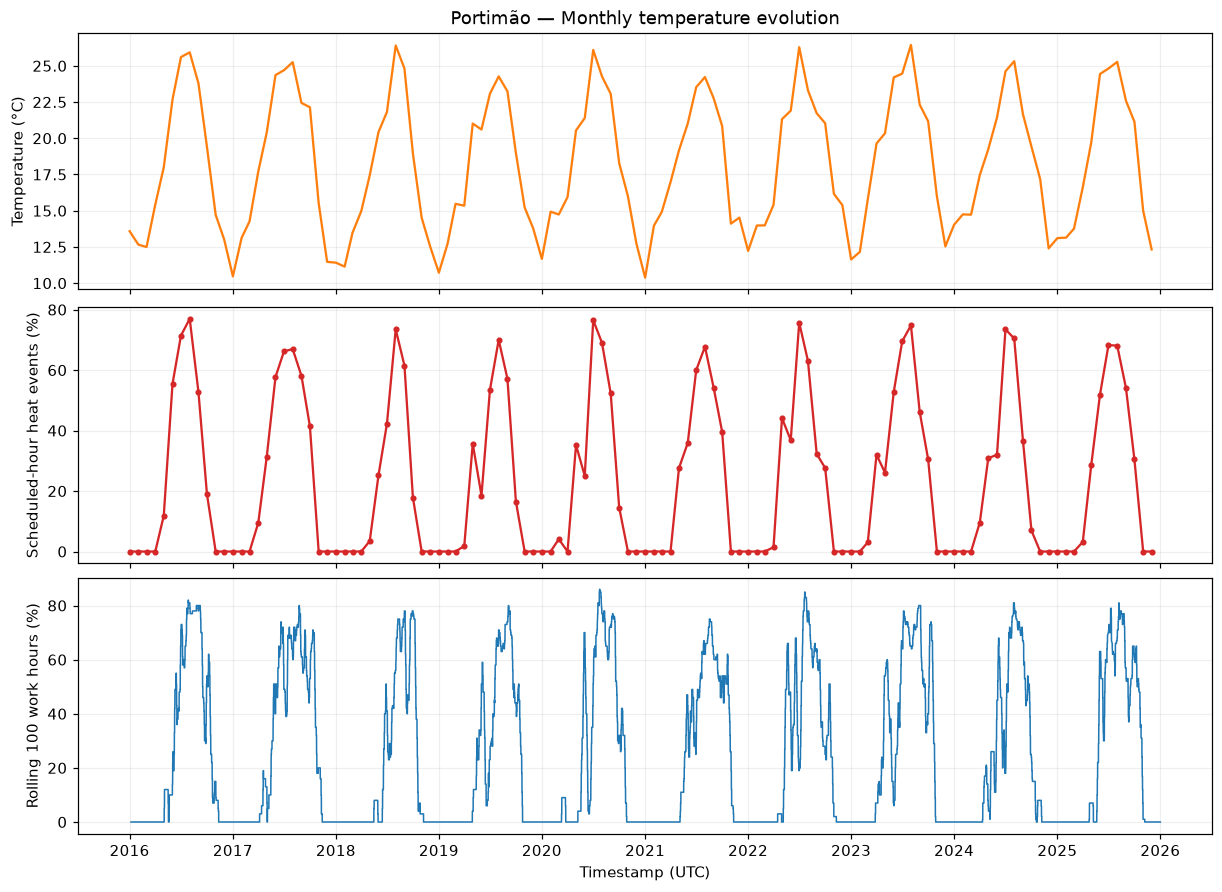

In [7]:
def observed_shift(city):
    stream = stream_full[city]
    return stream.loc[stream['eligible_shift'] & stream['y_event'].notna()].copy()


def consecutive_hot_episodes(work_hours):
    """Count contiguous one-hour hot-event runs; overnight gaps end a run."""
    hot = work_hours.loc[work_hours['y_event'].eq(1)]
    if hot.empty:
        return pd.Series(dtype='int64', name='hours')
    run_ids = (hot.index.to_series().diff() != pd.Timedelta(hours=1)).cumsum()
    return hot.groupby(run_ids).size().rename('hours')


def city_statistics(city):
    work = observed_shift(city)
    actual_temperature = weather[city].loc[work.index, 'temperature_2m']
    episodes = consecutive_hot_episodes(work)
    day_counts = work.groupby('local_date')['y_event'].sum()
    row = {
        'city': city, 'observed_shift_hours': len(work),
        'heat_event_n': int(work['y_event'].sum()),
        'non_event_n': int((work['y_event'] == 0).sum()),
        'heat_event_rate_pct': 100 * float(work['y_event'].mean()),
        'temperature_mean_c': actual_temperature.mean(),
        'temperature_std_c': actual_temperature.std(),
        'temperature_p95_c': actual_temperature.quantile(.95),
        'temperature_max_c': actual_temperature.max(),
        'event_episode_n': len(episodes),
        'longest_episode_hours': int(episodes.max()) if len(episodes) else 0,
        'mean_episode_hours': episodes.mean() if len(episodes) else 0.0,
        'shift_days_3plus_events_pct': 100 * day_counts.ge(3).mean(),
    }
    monthly = work.groupby(pd.Grouper(freq='MS')).agg(
        observed_hours=('y_event', 'size'),
        event_hours=('y_event', 'sum'),
    )
    monthly['event_rate_pct'] = 100 * monthly['event_hours'] / monthly['observed_hours']
    description = weather[city][RAW_VARIABLES].describe().T
    description.index.name = 'variable'
    return row, monthly, description, episodes


def output_city(city, tag):
    stats, monthly, description, episodes = city_statistics(city)
    pd.DataFrame([stats]).to_csv(TABLES_DIR / f'city_{tag}_profile.csv', index=False)
    monthly.to_csv(TABLES_DIR / f'city_{tag}_monthly_events.csv')
    description.to_csv(TABLES_DIR / f'city_{tag}_weather_statistics.csv')
    episodes.to_frame().to_csv(TABLES_DIR / f'city_{tag}_event_episodes.csv', index=False)
    yearly = observed_shift(city).groupby(pd.Grouper(freq='YS'))['y_event'].agg(['size', 'sum'])
    yearly.columns = ['observed_hours', 'event_hours']
    yearly['non_event_hours'] = yearly['observed_hours'] - yearly['event_hours']
    yearly['event_rate_pct'] = 100 * yearly['event_hours'] / yearly['observed_hours']
    yearly.to_csv(TABLES_DIR / f'city_{tag}_yearly_class_distribution.csv')
    display(pd.DataFrame([stats]).round(2))
    display(description[['mean', 'std', 'min', '50%', 'max']].round(2))

    fig, ax = plt.subplots(
    3, 1, figsize=(11, 8),
    sharex=True, layout='constrained'
    )

    # 1. Monthly temperature
    monthly_temperature = weather[city]['temperature_2m'].resample('MS').mean()

    ax[0].plot(
        monthly_temperature.index,
        monthly_temperature.values,
        color='tab:orange'
    )
    ax[0].set(
        title=f'{city} — Monthly temperature evolution',
        ylabel='Temperature (°C)'
    )

    # 2. Monthly heat-event frequency
    ax[1].plot(
        monthly.index,
        monthly['event_rate_pct'].to_numpy(),
        marker='o',
        markersize=3,
        color='tab:red'
    )
    ax[1].set(ylabel='Scheduled-hour heat events (%)')

    # 3. Rolling event frequency
    weekly = (
        observed_shift(city)['y_event']
        .astype(float)
        .rolling(100, min_periods=30)
        .mean()
    )

    ax[2].plot(
        weekly.index,
        100 * weekly.to_numpy(),
        linewidth=1,
        color='tab:blue'
    )
    ax[2].set(
        ylabel='Rolling 100 work hours (%)',
        xlabel='Timestamp (UTC)'
    )

    for axis in ax:
        axis.grid(alpha=0.2)

    save_figure(f'city_{tag}_temporal_profile.png')
    return stats, monthly, episodes


city_a_profile, city_a_monthly, city_a_episodes = output_city(CITY_A, 'A')

## 4. City B — Covilhã
We apply **exactly the same descriptive functions, temporal windows and metrics** to Covilhã. This keeps the city analyses consistent while allowing each student to interpret their primary city independently.

C:\Users\diogo\AppData\Local\Temp\ipykernel_11304\436981801.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  run_ids = (hot.index.to_series().diff() != pd.Timedelta(hours=1)).cumsum()


,city,observed_shift_hours,heat_event_n,non_event_n,heat_event_rate_pct,temperature_mean_c,temperature_std_c,temperature_p95_c,temperature_max_c,event_episode_n,longest_episode_hours,mean_episode_hours,shift_days_3plus_events_pct
0,Covilhã,26090,3467,22623,13.29,16.34,7.65,30.1,39.4,615,10,5.64,21.81


,mean,std,min,50%,max
variable,,,,,
temperature_2m,14.14,7.47,-4.1,13.1,39.4
relative_humidity_2m,70.53,21.96,8.0,74.0,100.0
precipitation,0.11,0.45,0.0,0.0,11.3
wind_speed_10m,8.60,3.91,0.0,8.0,33.5


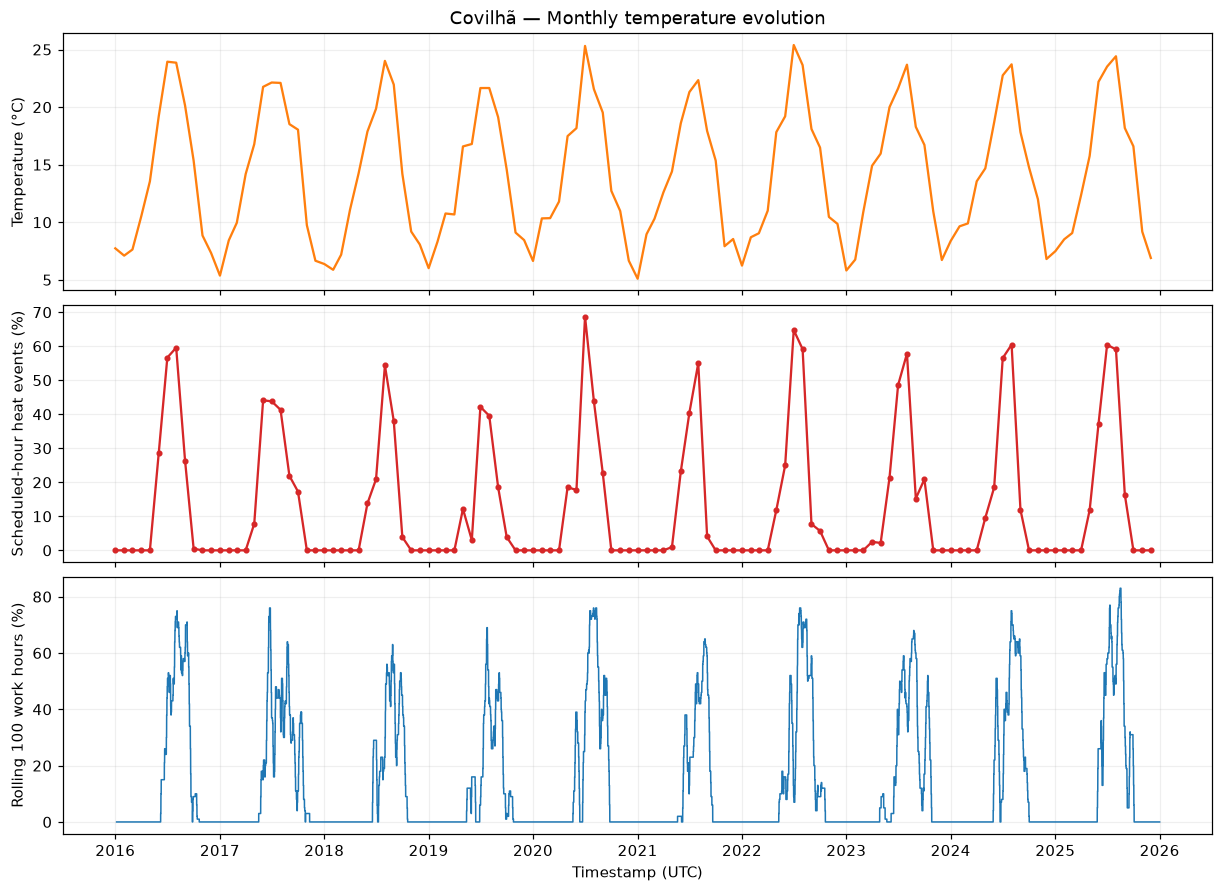

In [8]:
city_b_profile, city_b_monthly, city_b_episodes = output_city(CITY_B, 'B')

## 5. Comparative data analysis (before modelling)
We first compare **event exposure and persistence**, without using predictive accuracy as a proxy for city suitability. Two original visual analyses are provided: **(O1)** the month × shift-hour heat-event calendar and **(O2)** the distribution of consecutive heat-event durations. A shared colour scale and consistent denominators preserve comparability.

,observed_shift_hours,heat_event_n,non_event_n,heat_event_rate_pct,temperature_mean_c,temperature_std_c,temperature_p95_c,temperature_max_c,event_episode_n,longest_episode_hours,mean_episode_hours,shift_days_3plus_events_pct
city,,,,,,,,,,,,
Portimão,26090,6210,19880,23.80,21.00,6.50,32.4,41.3,975,10,6.37,35.22
Covilhã,26090,3467,22623,13.29,16.34,7.65,30.1,39.4,615,10,5.64,21.81


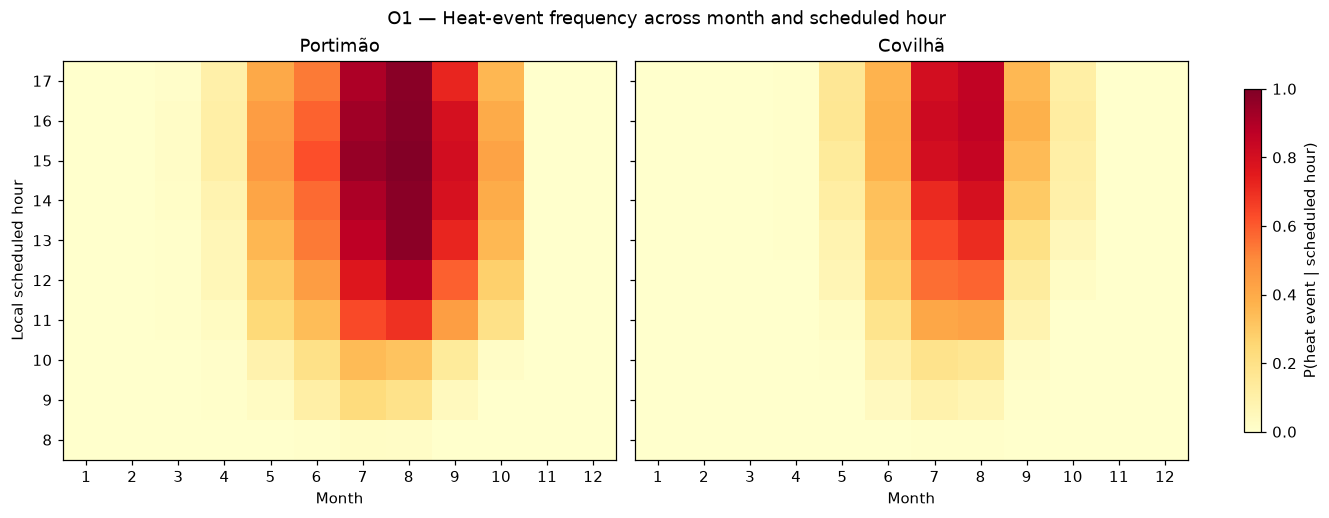

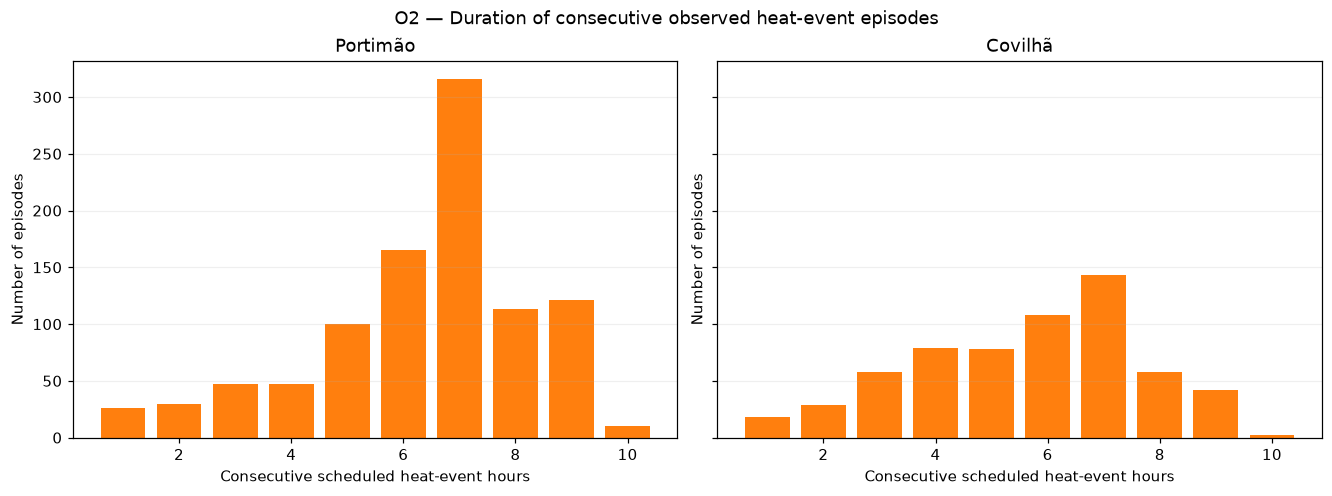

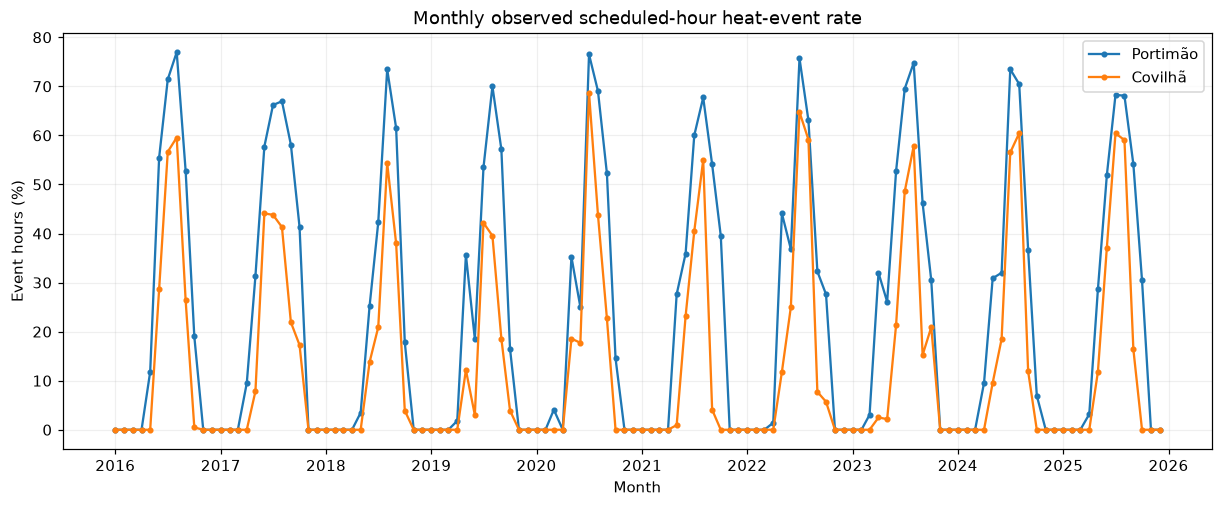

In [9]:
city_profiles = pd.DataFrame([city_a_profile, city_b_profile]).set_index('city')
display(city_profiles.round(2))
city_profiles.to_csv(TABLES_DIR / 'city_comparison.csv')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout='constrained')
images = []
for ax, city in zip(axes, CITIES):
    work = observed_shift(city)
    grid = work.pivot_table(index='local_hour', columns='local_month',
                            values='y_event', aggfunc='mean')
    grid = grid.reindex(index=range(SHIFT_START, SHIFT_END), columns=range(1, 13))
    image = ax.imshow(grid.to_numpy(dtype=float), origin='lower', aspect='auto',
                      vmin=0, vmax=1, cmap='YlOrRd')
    images.append(image)
    ax.set(title=city, xlabel='Month', xticks=range(12),
           xticklabels=list(range(1, 13)), yticks=range(SHIFT_END-SHIFT_START),
           yticklabels=list(range(SHIFT_START, SHIFT_END)))
axes[0].set_ylabel('Local scheduled hour')
fig.colorbar(images[0], ax=axes, shrink=.86, label='P(heat event | scheduled hour)')
fig.suptitle('O1 — Heat-event frequency across month and scheduled hour')
save_figure('O1_heat_exposure_calendar.png')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True, layout='constrained')
for ax, city, episodes in zip(axes, CITIES, (city_a_episodes, city_b_episodes)):
    if len(episodes):
        frequencies = episodes.value_counts().sort_index()
        ax.bar(frequencies.index, frequencies.values, width=.8, color='tab:orange')
    ax.set(title=city, xlabel='Consecutive scheduled heat-event hours',
           ylabel='Number of episodes')
    ax.grid(axis='y', alpha=.2)
fig.suptitle('O2 — Duration of consecutive observed heat-event episodes')
save_figure('O2_heat_episode_duration.png')

fig, ax = plt.subplots(figsize=(11, 4.5), layout='constrained')
for city, monthly in ((CITY_A, city_a_monthly), (CITY_B, city_b_monthly)):
    ax.plot(monthly.index, monthly['event_rate_pct'], marker='.', label=city)
ax.set(title='Monthly observed scheduled-hour heat-event rate',
       ylabel='Event hours (%)', xlabel='Month')
ax.grid(alpha=.2)
ax.legend()
save_figure('city_monthly_event_comparison.png')

## 6. Data Stream Mining experiment
### 6.1 Feature representations and models
We control one feature-related factor at a time. **A (4 features)** uses only the four previous-hour weather observations. **B (11 features)** adds one-hour temperature change, six-hour temperature mean and standard deviation, six-hour humidity mean, past-24-hour rainy-hour count, and cyclical hour-of-day. All rolling features end at *t−1*; the hour-of-day is known in advance. We use the same pooled warm-up preprocessing for each comparison.

The five mandatory incremental learners are implemented with **River**: Gaussian Naive Bayes, online Logistic Regression, Hoeffding Tree, Online Bagging, and Adaptive Random Forest. Each ensemble uses five base estimators for a manageable but genuinely streaming experiment. We store model settings and software versions alongside the metrics.

UnimSafe and UnimPA use the same feature columns and a five-rule budget. Each city and representation gets a fresh learner.

In [10]:
try:
    from river import ensemble, forest, linear_model, naive_bayes, optim, tree
except ImportError as error:
    raise ImportError('River is required for all five official models. '
                      'Install requirements.txt in this Jupyter kernel, restart, and Run All.') from error

if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from ENF_UnimNeuron_PA import EvolvingNeuroFuzzyUnimPA
from ENF_UnimNeuron_Safe import EvolvingNeuroFuzzyUnimSafe

FUZZY = {'UnimPA': EvolvingNeuroFuzzyUnimPA, 'UnimSafe': EvolvingNeuroFuzzyUnimSafe}

class FuzzyStreamModel:
    """Map named stream features to the supplied model's fixed column order."""
    def __init__(self, name, columns, seed=RANDOM_SEED, max_rules=5):
        self.columns = columns
        self.learner = FUZZY[name](
            n_features=len(columns),
            n_classes=2,
            max_rules=max_rules,
            random_state=seed,
        )

    def inputs(self, x):
        return np.array([[x[key] for key in self.columns]], dtype=float)

    def predict_one(self, x):
        return int(self.learner.predict(self.inputs(x))[0])

    def learn_one(self, x, y):
        self.learner.partial_fit(self.inputs(x), np.array([y]))

MODEL_NAMES = [
    'Gaussian Naive Bayes', 'Online Logistic Regression',
    'Hoeffding Tree', 'Online Bagging', 'Adaptive Random Forest', *FUZZY,
]
MODEL_PARAMETERS = {
    'Gaussian Naive Bayes': {'model': 'GaussianNB', 'settings': 'River defaults'},
    'Online Logistic Regression': {'model': 'LogisticRegression', 'sgd_lr': 0.05},
    'Hoeffding Tree': {'model': 'HoeffdingTreeClassifier', 'grace_period': 50,
                       'delta': .001, 'tau': .1, 'leaf_prediction': 'mc'},
    'Online Bagging': {'model': 'BaggingClassifier', 'n_models': ENSEMBLE_SIZE,
                       'base_model': 'HoeffdingTreeClassifier', 'seed': RANDOM_SEED},
    'Adaptive Random Forest': {'model': 'ARFClassifier', 'n_models': ENSEMBLE_SIZE,
                               'max_features': 'sqrt', 'lambda_value': 6,
                               'grace_period': 50, 'delta': .001,
                               'tau': .1, 'leaf_prediction': 'mc', 'seed': RANDOM_SEED},
}


for name, cls in FUZZY.items():
    MODEL_PARAMETERS[name] = {'model': cls.__name__, 'max_rules': 5, 'n_classes': 2,
                              'random_state': RANDOM_SEED, 'other_settings': 'source defaults'}

def make_tree():
    return tree.HoeffdingTreeClassifier(grace_period=50, delta=.001,
                                        tau=.1, leaf_prediction='mc')


def new_model(name, columns=REP_A, seed=RANDOM_SEED, max_rules=5):
    """Return a fresh learner for one replay."""
    if name in FUZZY:
        return FuzzyStreamModel(name, columns, seed=seed, max_rules=max_rules)
    if name == 'Gaussian Naive Bayes':
        return naive_bayes.GaussianNB()
    if name == 'Online Logistic Regression':
        return linear_model.LogisticRegression(optimizer=optim.SGD(.05))
    if name == 'Hoeffding Tree':
        return make_tree()
    if name == 'Online Bagging':
        return ensemble.BaggingClassifier(model=make_tree(),
                                          n_models=ENSEMBLE_SIZE, seed=seed)
    if name == 'Adaptive Random Forest':
        return forest.ARFClassifier(n_models=ENSEMBLE_SIZE, max_features='sqrt',
                                    lambda_value=6, grace_period=50, delta=.001,
                                    tau=.1, leaf_prediction='mc', seed=seed)
    raise KeyError(name)


for model_name in MODEL_NAMES:
    candidate_model = new_model(model_name)
    assert hasattr(candidate_model, 'predict_one') and hasattr(candidate_model, 'learn_one')
model_table = pd.DataFrame([
    {
        'Model': name,
        'Configuration': ', '.join(
            f'{key}={value}'
            for key, value in parameters.items()
        )
    }
    for name, parameters in MODEL_PARAMETERS.items()
])

display(model_table)
print('All seven learners initialized; River', installed_version('river'))

,Model,Configuration
0,Gaussian Naive Bayes,"model=GaussianNB, settings=River defaults"
1,Online Logistic Regression,"model=LogisticRegression, sgd_lr=0.05"
2,Hoeffding Tree,"model=HoeffdingTreeClassifier, grace_period=50..."
3,Online Bagging,"model=BaggingClassifier, n_models=5, base_mode..."
4,Adaptive Random Forest,"model=ARFClassifier, n_models=5, max_features=..."
5,UnimPA,"model=EvolvingNeuroFuzzyUnimPA, max_rules=5, n..."
6,UnimSafe,"model=EvolvingNeuroFuzzyUnimSafe, max_rules=5,..."


All seven learners initialized; River 0.24.2


### 6.2 Evaluation metrics and sequential replay
We score Accuracy, Macro-F1, positive-event Precision and Recall, and the **TN / FP / FN / TP** confusion matrix. The positive label is always 1. Where no positive prediction or event is available, the corresponding metric uses zero division → 0. We also time prediction and update steps **separately** in milliseconds per scored event. Checkpoint metrics show whether performance changes over time.

During warm-up the learner receives labeled 2016–2017 events without scoring them. During evaluation (2018–2025), we call `predict_one`, update our recorded metrics, and **only then** call `learn_one` with the same event's label.

In [11]:
def confusion_metrics(tn, fp, fn, tp):
    n = tn + fp + fn + tp
    precision_1 = tp / (tp + fp) if tp + fp else 0.0
    recall_1 = tp / (tp + fn) if tp + fn else 0.0
    precision_0 = tn / (tn + fn) if tn + fn else 0.0
    recall_0 = tn / (tn + fp) if tn + fp else 0.0
    f1_1 = 2 * precision_1 * recall_1 / (precision_1 + recall_1) if precision_1 + recall_1 else 0.0
    f1_0 = 2 * precision_0 * recall_0 / (precision_0 + recall_0) if precision_0 + recall_0 else 0.0
    return {
        'n_evaluated': n, 'accuracy': (tn + tp) / n if n else 0.0,
        'macro_f1': (f1_0 + f1_1) / 2,
        'precision_event': precision_1, 'recall_event': recall_1,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }


class OnlineScores:
    def __init__(self, window=ROLLING_SCORE_WINDOW):
        self.counts = np.zeros((2, 2), dtype=int)  # [actual, predicted]
        self.recent = deque(maxlen=window)

    def add(self, actual, predicted):
        self.counts[int(actual), int(predicted)] += 1
        self.recent.append((int(actual), int(predicted)))

    def snapshot(self):
        tn, fp, fn, tp = self.counts.ravel().tolist()
        report = confusion_metrics(tn, fp, fn, tp)
        recent_counts = np.zeros((2, 2), dtype=int)
        for actual, predicted in self.recent:
            recent_counts[actual, predicted] += 1
        report['rolling_macro_f1'] = confusion_metrics(*recent_counts.ravel())['macro_f1']
        return report


assert confusion_metrics(3, 1, 2, 4)['accuracy'] == .7
assert confusion_metrics(3, 1, 2, 4)['FN'] == 2
print('PASS — binary confusion-matrix and metric unit tests.')


def replay(city, representation, model_name, seed=RANDOM_SEED, max_rules=5):
    """Warm up on 2016–2017; predict, evaluate and learn during 2018–2025."""
    columns = REP_A if representation == 'A' else REP_B
    model = new_model(model_name, columns, seed=seed, max_rules=max_rules)
    X = scaled_inputs[(city, representation)]
    y = stream_full[city].loc[model_times, 'y_event'].astype(int)

    for timestamp in warm_times:
        model.learn_one(X.loc[timestamp].to_dict(), int(y.loc[timestamp]))

    identity = dict(
        city=city,
        representation=representation,
        model=model_name,
        seed=seed,
        max_rules=max_rules if model_name in FUZZY else None,
    )

    if model_name in FUZZY:
        rule_history.append(dict(**identity, n_evaluated=0, rules=model.learner.n_rules_))
    scores = OnlineScores()
    prediction_ns = update_ns = missing_predictions = 0
    checkpoints = []
    for number, timestamp in enumerate(eval_times, start=1):
        features = X.loc[timestamp].to_dict()
        actual = int(y.loc[timestamp])

        before = time.perf_counter_ns()
        raw_prediction = model.predict_one(features)
        prediction_ns += time.perf_counter_ns() - before
        if raw_prediction is None:
            missing_predictions += 1
        predicted = 0 if raw_prediction is None else int(raw_prediction)
        scores.add(actual, predicted)  # EVALUATE — the label has not reached the learner.

        before = time.perf_counter_ns()
        model.learn_one(features, actual)  # LEARN only after evaluation.
        update_ns += time.perf_counter_ns() - before

        if number == 1 or number % CHECKPOINT_EVERY == 0 or number == len(eval_times):
            if model_name in FUZZY:
                rule_history.append(dict(**identity, n_evaluated=number, rules=model.learner.n_rules_))
            checkpoints.append({
                'city': city, 'representation': representation,
                'model': model_name, 'timestamp_utc': str(timestamp),
                'seed': seed,
                **scores.snapshot(),
            })

    report = scores.snapshot()
    assert report['n_evaluated'] == len(eval_times)
    report.update({
        'city': city, 'representation': representation, 'model': model_name,
        'prediction_ms_per_event': prediction_ns / 1e6 / len(eval_times),
        'update_ms_per_event': update_ns / 1e6 / len(eval_times),
        'none_predictions': missing_predictions,
        'warmup_events': len(warm_times),
        'seed': seed,
        'evaluation_start_utc': str(eval_times.min()),
        'evaluation_end_utc': str(eval_times.max()),
        'target_threshold_c': HOT_THRESHOLD_C,
    })
    report.pop('rolling_macro_f1')  # Save time-varying values in checkpoints instead.
    if model_name in FUZZY:
        learner = model.learner
        unit, size = 'rules', learner.n_rules_
        config = scaler_config[representation]
        for i, rule in enumerate(learner.rules if seed == RANDOM_SEED else []):
            center = rule.center * np.array(config['scales']) + config['means']
            row = dict(**identity, rule=i + 1, support=rule.support, sigma_z=rule.sigma,
                       prediction_at_center=int(learner.predict(rule.center[None, :])[0]))
            for feature, value, weight in zip(model.columns, center, rule.w):
                row['center_' + feature] = value
                row['weight_' + feature] = weight
            if model_name == 'UnimPA':
                row['pa_event_minus_non_event'] = learner.W[i+1, 1] - learner.W[i+1, 0]
                row['pa_bias_difference'] = learner.W[0, 1] - learner.W[0, 0]
            else:
                row['rule_event_share'] = rule.class_probs()[1]
            rule_rows.append(row)
    elif model_name == 'Hoeffding Tree':
        unit, size = 'tree nodes', model.n_nodes
    elif model_name in ('Online Bagging', 'Adaptive Random Forest'):
        unit, size = 'active ensemble tree nodes', sum((member.n_nodes or 0) for member in model.models)
    elif model_name == 'Online Logistic Regression':
        unit, size = 'coefficients incl. intercept', len(model.weights) + 1
    else:
        unit, size = 'class-feature Gaussians', sum(len(distributions) for distributions in model.gaussians.values())
    complexity_rows.append(dict(**identity, unit=unit, final_size=size))
    return report, checkpoints

PASS — binary confusion-matrix and metric unit tests.


### 6.3 Run the complete controlled experiment
We run **2 cities × 2 representations × 7 models = 28 experiments; 28 experiments to 28 configurations × 10 seeds = 280 replays**. Results are generated from fresh model states without hyperparameter selection on the evaluation period. We save `results/metrics.csv`, `results/configurations.csv`, checkpoint histories and full confusion counts for direct auditing. Ensemble runs may take several minutes.

In [12]:
KEYS = ['city', 'representation', 'model']
PREDICTIVE = ['accuracy', 'macro_f1', 'precision_event', 'recall_event']
TIMING = ['prediction_ms_per_event', 'update_ms_per_event', 'total_ms_per_event']


def summarize_runs(frame, keys, measures):
    """One row per configuration: mean and sample SD across the ten seeds."""
    groups = frame.groupby(keys, sort=False)
    assert groups.size().eq(len(SEEDS)).all()
    assert groups['seed'].nunique().eq(len(SEEDS)).all()

    means = groups[measures].mean()
    deviations = groups[measures].std().add_suffix('_sd')
    return means.join(deviations).reset_index()


rule_history, rule_rows, complexity_rows = [], [], []
metrics_rows, checkpoint_rows, configuration_rows = [], [], []

for seed in SEEDS:
    for city in CITIES:
        for representation in ('A', 'B'):
            columns = REP_A if representation == 'A' else REP_B

            for model_name in MODEL_NAMES:
                result, points = replay(city, representation, model_name, seed=seed)
                metrics_rows.append(result)
                checkpoint_rows.extend(points)

                params = MODEL_PARAMETERS[model_name].copy()
                for field in ('seed', 'random_state'):
                    if field in params:
                        params[field] = seed

                configuration_rows.append({
                    'assignment': PA_CODE,
                    'city': city,
                    'representation': representation,
                    'model': model_name,
                    'features': json.dumps(columns),
                    'parameters': json.dumps(params),
                    'warmup_end_utc': str(WARMUP_END_UTC),
                    'evaluation_first_utc': str(eval_times.min()),
                    'evaluation_last_utc': str(eval_times.max()),
                    'target_threshold_c': HOT_THRESHOLD_C,
                    'random_seed': seed,
                    'river_version': installed_version('river'),
                })

    print(f'Completed seed {seed}')

per_seed = pd.DataFrame(metrics_rows)
per_seed['total_ms_per_event'] = (
    per_seed['prediction_ms_per_event'] + per_seed['update_ms_per_event']
)

assert len(per_seed) == 280
assert per_seed[['TN', 'FP', 'FN', 'TP']].sum(axis=1).eq(len(eval_times)).all()

# Original metric names now contain the means. Companion columns contain the SDs.
metrics = summarize_runs(per_seed, KEYS, PREDICTIVE + TIMING)

# Retain the original audit fields in metrics.csv.
groups = per_seed.groupby(KEYS, sort=False)
audit = groups[
    ['n_evaluated', 'warmup_events', 'evaluation_start_utc',
     'evaluation_end_utc', 'target_threshold_c']
].first()
counts = groups[['TN', 'FP', 'FN', 'TP', 'none_predictions']].mean()
metrics = metrics.merge(audit.join(counts).reset_index(), on=KEYS, validate='one_to_one')

metrics.to_csv(RESULTS_DIR / 'metrics.csv', index=False)
pd.DataFrame(configuration_rows).to_csv(RESULTS_DIR / 'configurations.csv', index=False)
metrics[KEYS + ['TN', 'FP', 'FN', 'TP']].to_csv(
    RESULTS_DIR / 'confusion_matrices.csv', index=False
)

# Average corresponding timestamps before drawing the existing rolling plots.
checkpoints = (
    pd.DataFrame(checkpoint_rows)
    .drop(columns='seed')
    .groupby(KEYS + ['timestamp_utc'], as_index=False)
    .mean(numeric_only=True)
)
checkpoints.to_csv(RESULTS_DIR / 'checkpoints.csv', index=False)

display(metrics[KEYS + [
    'macro_f1', 'macro_f1_sd', 'precision_event', 'precision_event_sd',
    'recall_event', 'recall_event_sd', 'total_ms_per_event', 'total_ms_per_event_sd',
]].round(5))

Completed seed 42
Completed seed 43
Completed seed 44
Completed seed 45
Completed seed 46
Completed seed 47
Completed seed 48
Completed seed 49
Completed seed 50
Completed seed 51


,city,representation,model,macro_f1,macro_f1_sd,precision_event,precision_event_sd,recall_event,recall_event_sd,total_ms_per_event,total_ms_per_event_sd
0,Portimão,A,Gaussian Naive Bayes,0.86642,0.00000,0.68783,0.00000,0.97940,0.00000,0.07023,0.00180
1,Portimão,A,Online Logistic Regression,0.94826,0.00000,0.92582,0.00000,0.91514,0.00000,0.00600,0.00019
2,Portimão,A,Hoeffding Tree,0.95001,0.00000,0.94321,0.00000,0.90319,0.00000,0.01164,0.00036
3,Portimão,A,Online Bagging,0.95183,0.00106,0.95035,0.00401,0.90194,0.00510,0.06225,0.00297
4,Portimão,A,Adaptive Random Forest,0.94310,0.00171,0.92600,0.00281,0.89895,0.00319,0.09755,0.00276
5,Portimão,A,UnimPA,0.92348,0.00000,0.89953,0.00000,0.86488,0.00000,0.22934,0.00687
6,Portimão,A,UnimSafe,0.75817,0.00000,0.63604,0.00000,0.61874,0.00000,0.18234,0.00653
7,Portimão,B,Gaussian Naive Bayes,0.85927,0.00000,0.68220,0.00000,0.95901,0.00000,0.07827,0.00297
8,Portimão,B,Online Logistic Regression,0.95607,0.00000,0.93210,0.00000,0.93306,0.00000,0.00823,0.00029
9,Portimão,B,Hoeffding Tree,0.96192,0.00000,0.92460,0.00000,0.95984,0.00000,0.01735,0.00078


## 7. Results — evidence tables and figures
We export the mandatory model metrics and confusion matrices for both feature representations and both cities. Additional controlled comparisons show **B − A** in Macro-F1 and event Recall, while cost-versus-detection plots retain the distinction between predictive value and computational expense.

,city,accuracy,macro_f1,recall_event,FN
0,Portimão,0.7675,0.4342,0.0,4855
1,Covilhã,0.8705,0.4654,0.0,2703


,city,model,accuracy_B_minus_A,macro_f1_B_minus_A,recall_event_B_minus_A
0,Covilhã,Adaptive Random Forest,-0.0016,-0.0038,-0.0126
1,Covilhã,Gaussian Naive Bayes,-0.0174,-0.0270,-0.0067
2,Covilhã,Hoeffding Tree,0.0032,0.0070,0.0107
3,Covilhã,Online Bagging,0.0053,0.0121,0.0253
4,Covilhã,Online Logistic Regression,0.0006,0.0014,0.0067
5,Covilhã,UnimPA,-0.0162,-0.0340,-0.0303
6,Covilhã,UnimSafe,0.0069,0.1381,0.2642
7,Portimão,Adaptive Random Forest,0.0003,0.0004,-0.0019
8,Portimão,Gaussian Naive Bayes,-0.0053,-0.0072,-0.0204
9,Portimão,Hoeffding Tree,0.0076,0.0119,0.0566


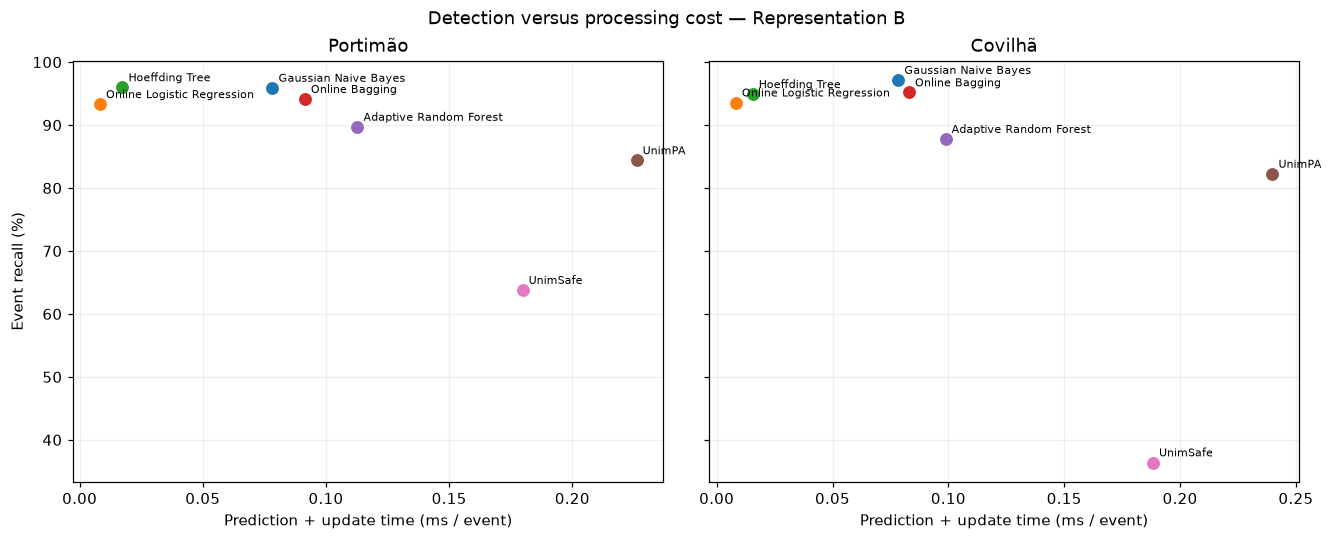

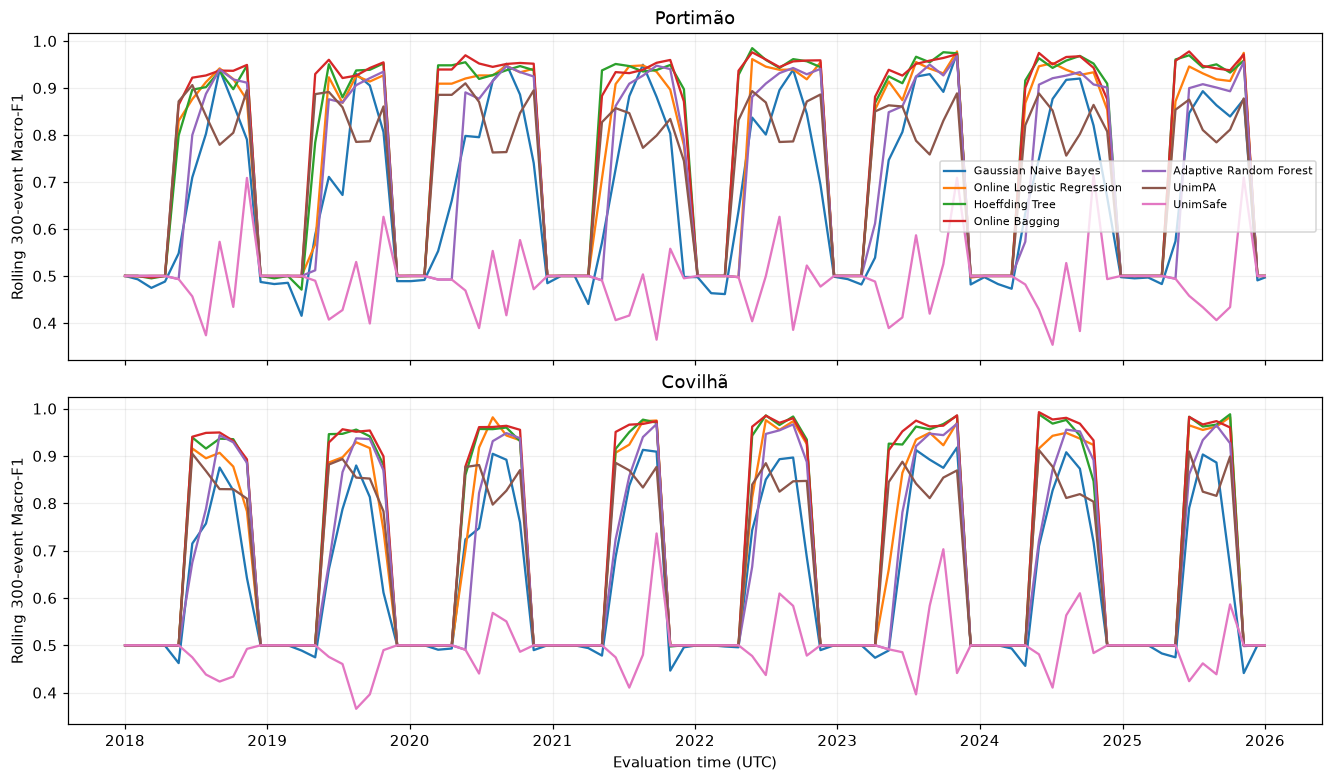

In [13]:
# The identical baseline (always predict no heat event) contextualises class imbalance.
baseline_rows = []
for city in CITIES:
    actual = stream_full[city].loc[eval_times, 'y_event'].astype(int)
    baseline_rows.append({
        'city': city, 'baseline': 'Always predict no event',
        **confusion_metrics(int((actual == 0).sum()), 0, int((actual == 1).sum()), 0),
    })
baseline = pd.DataFrame(baseline_rows)
baseline.to_csv(TABLES_DIR / 'always_negative_baseline.csv', index=False)
display(baseline[['city', 'accuracy', 'macro_f1', 'recall_event', 'FN']].round(4))

wide = metrics.pivot(index=['city', 'model'], columns='representation',
                     values=['macro_f1', 'recall_event', 'accuracy'])
representation_delta = pd.DataFrame({
    f'{score}_B_minus_A': wide[(score, 'B')] - wide[(score, 'A')]
    for score in ('accuracy', 'macro_f1', 'recall_event')
}).reset_index()
representation_delta.to_csv(TABLES_DIR / 'representation_B_minus_A.csv', index=False)
display(representation_delta.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout='constrained')
for ax, city in zip(axes, CITIES):
    subset = metrics.loc[(metrics['city'] == city) & (metrics['representation'] == 'B')]
    total_cost = subset['prediction_ms_per_event'] + subset['update_ms_per_event']
    for (_, result), x_value in zip(subset.iterrows(), total_cost):
        ax.scatter(x_value, result['recall_event'] * 100, s=55)
        ax.annotate(result['model'], (x_value, result['recall_event'] * 100),
                    xytext=(4, 4), textcoords='offset points', fontsize=7)
    ax.set(title=city, xlabel='Prediction + update time (ms / event)')
    ax.grid(alpha=.2)
axes[0].set_ylabel('Event recall (%)')
fig.suptitle('Detection versus processing cost — Representation B')
save_figure('model_recall_vs_cost.png')

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout='constrained')
for ax, city in zip(axes, CITIES):
    for model_name in MODEL_NAMES:
        subset = checkpoints.loc[(checkpoints['city'] == city) &
                                 (checkpoints['representation'] == 'B') &
                                 (checkpoints['model'] == model_name)]
        ax.plot(pd.to_datetime(subset['timestamp_utc'], utc=True),
                subset['rolling_macro_f1'], label=model_name)
    ax.set(title=city, ylabel=f'Rolling {ROLLING_SCORE_WINDOW}-event Macro-F1')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=7, ncol=2)
axes[1].set_xlabel('Evaluation time (UTC)')
save_figure('model_rolling_macro_f1.png')

### 7.3 Model complexity and fuzzy rule structure
Compare final sizes within each model family. Fuzzy snapshots track the number of rules after warm-up and at each score checkpoint. Final rule centres are in the original feature units. Support counts premise assignments. A Safe rule reports its event share and a PA rule its signed contribution per unit of normalized activation. Prediction at the centre uses the entire model. Rule numbers identify final slots only.

,city,representation,model,unit,final_size,final_size_sd
0,Portimão,A,Gaussian Naive Bayes,class-feature Gaussians,8.0,0.00
1,Portimão,A,Online Logistic Regression,coefficients incl. intercept,5.0,0.00
2,Portimão,A,Hoeffding Tree,tree nodes,39.0,0.00
3,Portimão,A,Online Bagging,active ensemble tree nodes,207.4,15.37
4,Portimão,A,Adaptive Random Forest,active ensemble tree nodes,56.2,29.79
5,Portimão,A,UnimPA,rules,5.0,0.00
6,Portimão,A,UnimSafe,rules,5.0,0.00
7,Portimão,B,Gaussian Naive Bayes,class-feature Gaussians,22.0,0.00
8,Portimão,B,Online Logistic Regression,coefficients incl. intercept,12.0,0.00
9,Portimão,B,Hoeffding Tree,tree nodes,33.0,0.00


,city,representation,model,seed,max_rules,rule,support,sigma_z,prediction_at_center,center_lag1_temperature_2m,...,center_temperature_std_6h,weight_temperature_std_6h,center_humidity_mean_6h,weight_humidity_mean_6h,center_rainy_hours_24h,weight_rainy_hours_24h,center_shift_hour_sin,weight_shift_hour_sin,center_shift_hour_cos,weight_shift_hour_cos
23,Covilhã,A,UnimPA,42,5,4,7766,1.507,0,22.980,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28,Covilhã,A,UnimSafe,42,5,4,7766,1.507,0,22.980,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
32,Covilhã,B,UnimPA,42,5,3,10868,2.434,0,12.457,...,1.370,1.000,79.275,1.000,1.157,1.000,0.349,1.000,-0.806,1.000
37,Covilhã,B,UnimSafe,42,5,3,10868,2.434,0,12.457,...,1.370,0.091,79.275,0.091,1.157,0.091,0.349,0.091,-0.806,0.091
0,Portimão,A,UnimPA,42,5,1,4847,1.372,0,16.001,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Portimão,A,UnimSafe,42,5,1,4847,1.372,0,16.001,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,Portimão,B,UnimPA,42,5,1,1020,2.260,0,19.778,...,2.138,1.000,74.015,1.000,1.125,1.000,-0.297,1.000,-0.896,1.000
15,Portimão,B,UnimSafe,42,5,1,1020,2.260,0,19.778,...,2.138,0.091,74.015,0.091,1.125,0.091,-0.297,0.091,-0.896,0.091


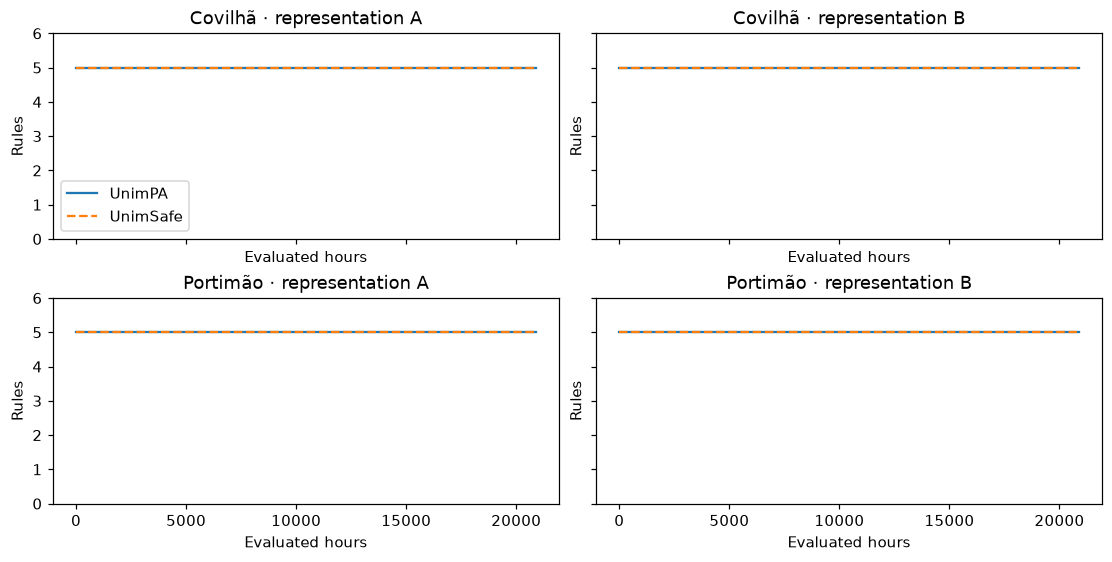

In [14]:
complexity = pd.DataFrame(complexity_rows)
rules = pd.DataFrame(rule_rows)  # actual final rules from seed 42

assert len(complexity) == len(per_seed)

size_summary = summarize_runs(complexity, KEYS + ['unit'], ['final_size'])
size_summary.to_csv(TABLES_DIR / 'model_complexity.csv', index=False)
display(size_summary.round(2))

history = (
    pd.DataFrame(rule_history)
    .groupby(KEYS + ['n_evaluated'], as_index=False)['rules']
    .mean()
)
assert history['rules'].between(1, 5).all()
history.to_csv(TABLES_DIR / 'rule_history.csv', index=False)

# Largest-support final premise for each city, representation and fuzzy learner.
examples = rules.loc[rules.groupby(['city', 'representation', 'model']).support.idxmax()]
display(examples.dropna(axis=1, how='all').round(3))
fig, axes = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(10, 5), layout='constrained')
for ax, ((city, rep), subset) in zip(axes.flat, history.groupby(['city', 'representation'])):
    for name, group in subset.groupby('model'):
        ax.step(group.n_evaluated, group.rules, where='post', label=name,
                linestyle='--' if name == 'UnimSafe' else '-')
    ax.set(title=f'{city} · representation {rep}', xlabel='Evaluated hours', ylabel='Rules', ylim=(0, 6))
axes.flat[0].legend()
save_figure('fuzzy_rule_counts.png')

**Reading the rule results.** Both variants reached the five-rule cap before evaluation and had five rules at every checkpoint. In Portimão with representation A, their warmest final premise was centred on 25.92 °C and 43.2% humidity. UnimPA gave that slot a positive event-score contribution (+22.59 per unit of normalized activation), while UnimSafe’s local event share was 0.004. Both models predicted a non-event at this centre when all five rules voted. These December snapshots describe the final model state. The full replay gives a different view of the models: in Covilhã with A, UnimPA detected 85.3% of hot hours and UnimSafe detected 10.0%.

## 8. Rule-budget tuning for UnimPA and UnimSafe
The main replay in §6–7 keeps both fuzzy learners at the default five-rule budget. In this section we tune only that budget, `max_rules`, and keep every other setting at its source default. The evaluation stream is not used to choose it:

| Step | Data | Role |
|---|---|---|
| Fit | 2016 work hours, learn only | Train each candidate from a fresh state |
| Validate | 2017 work hours, predict → score → learn | Selection score |
| Held-out check | 2018–2025, the same replay as §6.3 | Reported only, never used to choose |

- **Grid:** `max_rules` = 1, 4, 7, …, 100 (34 values in steps of 3), plus the default 5 as a reference. That gives 35 values × 2 learners × 2 representations × 2 cities = 280 validation runs. They run in parallel on all CPU cores and may take a few minutes.
- **Preprocessing:** median imputation and scaling for the inner loop are refitted on pooled 2016 data only, so the 2017 validation features are also out-of-sample.
- **Selection:** the highest 2017 Macro-F1 averaged over the two cities, chosen separately for each learner and representation. Ties go to fewer rules.
- **The models in §6–7 are not changed.** This section only reports what a tuned budget would do.

In [15]:
from joblib import Parallel, delayed

MAX_RULES_GRID = sorted(set(range(1, 101, 3)) | {5})  # step-3 grid plus the default budget
INNER_FIT_END = pd.Timestamp('2016-12-31 23:00:00', tz='UTC')
inner_fit_times = warm_times[warm_times <= INNER_FIT_END]

# Imputation and scaling for the inner loop use pooled 2016 statistics only.
pooled_2016 = pd.concat([stream_full[city].loc[inner_fit_times, REP_B] for city in CITIES],
                        ignore_index=True)
medians_2016 = pooled_2016.median(numeric_only=True)
inner_inputs = {}
for representation, features in (('A', REP_A), ('B', REP_B)):
    scaler_2016 = StandardScaler().fit(pooled_2016[features].fillna(medians_2016))
    for city in CITIES:
        inner_inputs[(city, representation)] = scaler_2016.transform(
            stream_full[city].loc[warm_times, features].fillna(medians_2016))
warm_labels = {city: stream_full[city].loc[warm_times, 'y_event'].astype(int).to_numpy()
               for city in CITIES}


def fuzzy_prequential(family, max_rules, X, y, n_learn):
    # Learn the first n_learn rows, then predict -> score -> learn on every later row.
    learner = FUZZY[family](n_features=X.shape[1], n_classes=2,
                            max_rules=max_rules, random_state=RANDOM_SEED)
    learner.partial_fit(X[:n_learn], y[:n_learn])
    counts = np.zeros((2, 2), dtype=int)  # [actual, predicted]
    for i in range(n_learn, len(y)):
        counts[y[i], int(learner.predict(X[i:i + 1])[0])] += 1
        learner.partial_fit(X[i:i + 1], y[i:i + 1])
    return {**confusion_metrics(*counts.ravel().tolist()), 'final_rules': learner.n_rules_}


search_jobs = [(family, rep, city, k) for family in FUZZY for rep in ('A', 'B')
               for city in CITIES for k in MAX_RULES_GRID]
search_start = time.perf_counter()
search_results = Parallel(n_jobs=-1, max_nbytes=None)(
    delayed(fuzzy_prequential)(family, k, inner_inputs[(city, rep)], warm_labels[city],
                               len(inner_fit_times))
    for family, rep, city, k in search_jobs)
max_rules_trials = pd.DataFrame([dict(model=f, representation=r, city=c, max_rules=k, **res)
                                 for (f, r, c, k), res in zip(search_jobs, search_results)])
max_rules_trials.to_csv(TABLES_DIR / 'fuzzy_max_rules_validation.csv', index=False)
print(f'{len(search_jobs)} validation runs in {(time.perf_counter() - search_start) / 60:.1f} min '
      f'({len(inner_fit_times):,} fit hours and {len(warm_times) - len(inner_fit_times):,} '
      f'validation hours per city).')

280 validation runs in 2.6 min (2,610 fit hours and 2,600 validation hours per city).


selected_max_rules  val_macro_f1_default_5  \
model    representation                                               
UnimPA   A                                4                  0.9003   
         B                                4                  0.8919   
UnimSafe A                               13                  0.6115   
         B                                7                  0.6623   

                         val_macro_f1_selected  rules_used_with_cap_100  
model    representation                                                  
UnimPA   A                              0.9058                     54.5  
         B                              0.8919                     40.5  
UnimSafe A                              0.6289                     54.5  
         B                              0.6627                     40.5

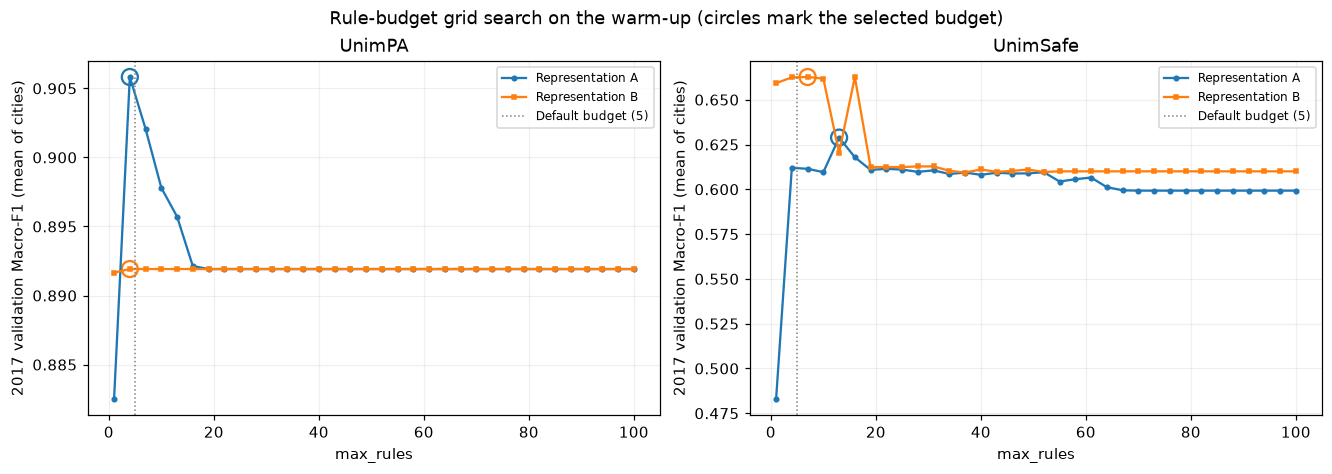

In [16]:
validation_curve = (max_rules_trials
                    .groupby(['model', 'representation', 'max_rules'], as_index=False)
                    .agg(val_macro_f1=('macro_f1', 'mean'), final_rules=('final_rules', 'mean')))
selected_rules = (validation_curve
                  .sort_values(['val_macro_f1', 'max_rules'], ascending=[False, True])
                  .groupby(['model', 'representation']).head(1)
                  .set_index(['model', 'representation']).sort_index())
by_budget = validation_curve.set_index(['model', 'representation', 'max_rules'])
selection_table = pd.DataFrame({
    'selected_max_rules': selected_rules['max_rules'],
    'val_macro_f1_default_5': by_budget.xs(5, level='max_rules')['val_macro_f1'],
    'val_macro_f1_selected': selected_rules['val_macro_f1'],
    'rules_used_with_cap_100': by_budget.xs(100, level='max_rules')['final_rules'],
})
selection_table.to_csv(TABLES_DIR / 'fuzzy_max_rules_selection.csv')
display(selection_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout='constrained')
for ax, family in zip(axes, FUZZY):
    for rep, marker in (('A', 'o'), ('B', 's')):
        curve = validation_curve.loc[(validation_curve['model'] == family) &
                                     (validation_curve['representation'] == rep) &
                                     validation_curve['max_rules'].isin(range(1, 101, 3))]
        line, = ax.plot(curve['max_rules'], curve['val_macro_f1'], marker=marker,
                        markersize=3, label=f'Representation {rep}')
        best = selected_rules.loc[(family, rep)]
        ax.scatter(best['max_rules'], best['val_macro_f1'], s=110, facecolors='none',
                   edgecolors=line.get_color(), linewidths=1.5)
    ax.axvline(5, color='grey', linestyle=':', linewidth=1, label='Default budget (5)')
    ax.set(title=family, xlabel='max_rules', ylabel='2017 validation Macro-F1 (mean of cities)')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.suptitle('Rule-budget grid search on the warm-up (circles mark the selected budget)')
save_figure('fuzzy_max_rules_tuning.png')

In [17]:
# Recover the ten fixed-cap runs already completed in Section 6.
fixed = per_seed.loc[per_seed['model'].isin(FUZZY)].merge(
    complexity[KEYS + ['seed', 'final_size']],
    on=KEYS + ['seed'],
    validate='one_to_one',
).assign(budget='Fixed', max_rules=5)

tuned_rows, tuned_rule_rows = [], []

for (family, rep), choice in selected_rules.iterrows():
    cap = int(choice['max_rules'])

    for city in CITIES:
        match = (
            (fixed['city'] == city)
            & (fixed['representation'] == rep)
            & (fixed['model'] == family)
        )

        # If tuning selects five, the fixed and tuned models are the same fit.
        if cap == 5:
            tuned_rows.extend(fixed.loc[match].to_dict('records'))
            same_rules = rules.query(
                'city == @city and representation == @rep and model == @family'
            )
            tuned_rule_rows.extend(same_rules.to_dict('records'))
            continue

        for seed in SEEDS:
            # replay() writes diagnostics into these three lists.
            # Keep the tuned entries separate so rerunning this cell is safe.
            r0, h0, c0 = len(rule_rows), len(rule_history), len(complexity_rows)
            try:
                result, _ = replay(city, rep, family, seed=seed, max_rules=cap)
                result['max_rules'] = cap
                result['final_size'] = complexity_rows[-1]['final_size']
                result['total_ms_per_event'] = (
                    result['prediction_ms_per_event'] + result['update_ms_per_event']
                )
                tuned_rows.append(result)
                tuned_rule_rows.extend(rule_rows[r0:])
            finally:
                del rule_rows[r0:]
                del rule_history[h0:]
                del complexity_rows[c0:]

tuned = pd.DataFrame(tuned_rows).assign(budget='Tuned')
budget_runs = pd.concat([fixed, tuned], ignore_index=True)

# Keep the original side-by-side layout: one row per city, representation and model.
measures = PREDICTIVE + TIMING + ['final_size']
budget_summary = summarize_runs(budget_runs, KEYS + ['budget'], measures)
wide = budget_summary.set_index(KEYS + ['budget']).unstack('budget')
wide.columns = [
    f"{metric}_{'default_5' if budget == 'Fixed' else 'selected'}"
    for metric, budget in wide.columns
]
held_out_check = wide.reset_index()

caps = selected_rules['max_rules'].rename('selected_max_rules').reset_index()
held_out_check = held_out_check.merge(caps, on=['model', 'representation'])

# Compare the two caps within the same seed before summarizing their difference.
paired = budget_runs.pivot(index=KEYS + ['seed'], columns='budget', values='macro_f1')
paired['delta_macro_f1'] = paired['Tuned'] - paired['Fixed']
delta = summarize_runs(paired.reset_index(), KEYS, ['delta_macro_f1'])
held_out_check = held_out_check.merge(delta, on=KEYS, validate='one_to_one')

held_out_check.to_csv(TABLES_DIR / 'fuzzy_max_rules_held_out.csv', index=False)
display(held_out_check[KEYS + [
    'selected_max_rules', 'macro_f1_default_5', 'macro_f1_selected',
    'delta_macro_f1', 'delta_macro_f1_sd',
    'recall_event_default_5', 'recall_event_selected',
]].round(4))

,city,representation,model,selected_max_rules,macro_f1_default_5,macro_f1_selected,delta_macro_f1,delta_macro_f1_sd,recall_event_default_5,recall_event_selected
0,Covilhã,A,UnimPA,4,0.9320,0.8892,-0.0428,0.0,0.8528,0.7925
1,Covilhã,A,UnimSafe,13,0.5538,0.5916,0.0378,0.0,0.0999,0.1546
2,Covilhã,B,UnimPA,4,0.8980,0.8981,0.0001,0.0,0.8224,0.8224
3,Covilhã,B,UnimSafe,7,0.6919,0.6916,-0.0002,0.0,0.3640,0.3633
4,Portimão,A,UnimPA,4,0.9235,0.9107,-0.0128,0.0,0.8649,0.8492
5,Portimão,A,UnimSafe,13,0.7582,0.7622,0.0040,0.0,0.6187,0.6344
6,Portimão,B,UnimPA,4,0.8983,0.8983,0.0000,0.0,0.8439,0.8439
7,Portimão,B,UnimSafe,7,0.7618,0.7636,0.0018,0.0,0.6379,0.6410


**Reading the tuning results.**

- **Selected budgets on 2017 validation:**
  - UnimPA: 4 rules for both A and B.
  - UnimSafe: 13 rules for A and 7 for B.

  The gains over the default five are small: +0.006 for UnimPA A, +0.017 for UnimSafe A, and +0.0004 for UnimSafe B. UnimPA B is tied, so the smallest tied budget is kept.
- **The right half of the grid is flat because the cap stops binding.** Left uncapped, both learners grow to about 54 rules (A) and 40 rules (B) on the warm-up stream. Every cap above roughly 70 (A) or 58 (B) therefore gives identical results.
- **UnimPA's predictions stop changing early.** Its 2017 score is identical (0.8919) for any cap of 4 or more on B, and 19 or more on A.
- **Large budgets slightly hurt UnimSafe.** On B it falls from about 0.66 to 0.61 once the cap passes about 18 rules. On A it eases from about 0.61 to 0.60 beyond about 60 rules.
- **The held-out check (2018–2025) shows the tuned budgets do not carry over reliably:**
  - UnimPA with 4 rules is worse than the default on A (Portimão −0.013, Covilhã −0.043) and unchanged on B.
  - UnimSafe improves on A (Portimão +0.004, Covilhã +0.038, where event recall rises from 0.10 to 0.15) and is essentially unchanged on B (+0.002 and −0.0002).
- **Conclusion:** for these learners the rule budget is a weak, noisy lever. The default of five rules is a reasonable setting, and we keep it in the main experiment.


## 9. Interpreting the final UnimPA and UnimSafe rules

We compare the final rules under the fixed five-rule budget and the cap selected
on 2017 validation data. Each row describes one actual rule from seed 42.
Centres are shown in the original weather units. Support counts assignments to
the premise, and prediction at the centre uses the entire fitted classifier.

UnimPA | Portimão | representation A | seed 42


,budget,max_rules,rule,support,center_lag1_temperature_2m,center_lag1_relative_humidity_2m,center_lag1_precipitation,center_lag1_wind_speed_10m,pa_event_minus_non_event,prediction_at_center
0,Fixed,5,1,4847,16.001,77.880,0.014,9.211,-2.112,0
1,Fixed,5,2,1865,16.562,78.928,0.040,18.885,-7.073,0
2,Fixed,5,3,3983,25.917,43.214,0.002,14.708,22.592,0
3,Fixed,5,4,1122,17.876,54.984,0.008,20.688,6.898,0
4,Fixed,5,5,125,17.454,82.568,0.357,20.983,-23.444,0
40,Tuned,4,1,3107,17.248,72.526,0.016,10.985,-5.056,0
41,Tuned,4,2,641,17.077,78.496,0.063,18.449,-20.072,0
42,Tuned,4,3,2714,24.042,48.191,0.004,14.799,20.500,0
43,Tuned,4,4,996,17.844,60.728,0.011,18.434,2.490,0


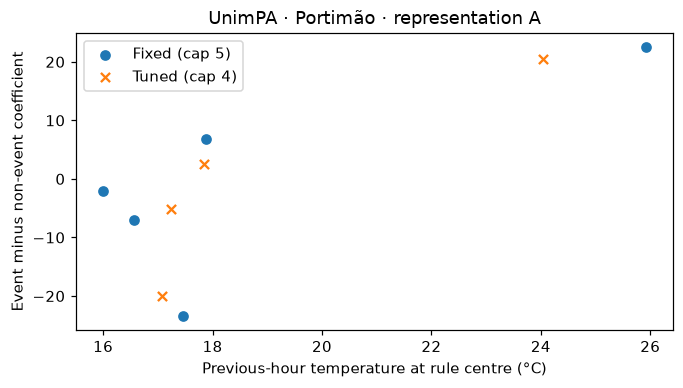

UnimSafe | Portimão | representation A | seed 42


,budget,max_rules,rule,support,center_lag1_temperature_2m,center_lag1_relative_humidity_2m,center_lag1_precipitation,center_lag1_wind_speed_10m,rule_event_share,prediction_at_center
5,Fixed,5,1,4847,16.001,77.880,0.014,9.211,0.003,0
6,Fixed,5,2,1865,16.562,78.928,0.040,18.885,0.003,0
7,Fixed,5,3,3983,25.917,43.214,0.002,14.708,0.004,0
8,Fixed,5,4,1122,17.876,54.984,0.008,20.688,0.003,0
9,Fixed,5,5,125,17.454,82.568,0.357,20.983,0.003,0
56,Tuned,13,1,2850,17.216,81.874,0.017,9.059,0.003,0
57,Tuned,13,2,1223,12.690,85.265,0.014,14.319,0.003,0
58,Tuned,13,3,793,17.107,80.719,0.016,21.419,0.003,0
59,Tuned,13,4,191,19.630,76.246,0.203,23.399,0.003,0
60,Tuned,13,5,365,16.629,86.312,0.381,18.669,0.003,0


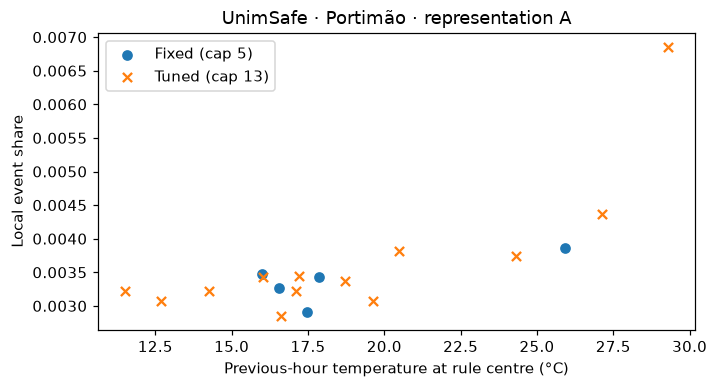

In [18]:
rule_book = pd.concat([
    rules.assign(budget='Fixed'),
    pd.DataFrame(tuned_rule_rows).assign(budget='Tuned'),
], ignore_index=True)

# Replace the existing rule file with the combined fixed-and-tuned table.
rule_book.to_csv(TABLES_DIR / 'final_rules.csv', index=False)

# Change these to inspect Covilhã or representation B.
city_to_show, rep_to_show = CITY_A, 'A'
detail = rule_book.query('city == @city_to_show and representation == @rep_to_show')

weather = [
    'center_lag1_temperature_2m',
    'center_lag1_relative_humidity_2m',
    'center_lag1_precipitation',
    'center_lag1_wind_speed_10m',
]

for family, evidence, label in [
    ('UnimPA', 'pa_event_minus_non_event', 'Event minus non-event coefficient'),
    ('UnimSafe', 'rule_event_share', 'Local event share'),
]:
    view = detail.loc[detail['model'].eq(family)].sort_values(['budget', 'rule'])

    print(f'{family} | {city_to_show} | representation {rep_to_show} | seed 42')
    display(view[[
        'budget', 'max_rules', 'rule', 'support', *weather,
        evidence, 'prediction_at_center',
    ]].round(3))

    fig, ax = plt.subplots(figsize=(7, 3.5))
    for budget, group in view.groupby('budget'):
        ax.scatter(
            group['center_lag1_temperature_2m'], group[evidence],
            marker='o' if budget == 'Fixed' else 'x',
            label=f"{budget} (cap {group['max_rules'].iloc[0]})",
        )
    ax.set(
        xlabel='Previous-hour temperature at rule centre (°C)',
        ylabel=label,
        title=f'{family} · {city_to_show} · representation {rep_to_show}',
    )
    ax.legend()
    plt.show()
    plt.close(fig)

In [ ]:
print(f"Total notebook runtime: {time.time() - notebook_start:.2f} seconds")